# eBay-style Marketplace Analytics with Apache Spark (FA2)

**Group members:** [add names]

**Context.** Our FA1 case study was **eBay**. eBay publishes no transaction data, so we use the **Olist Brazilian marketplace dataset**
(independent sellers selling to buyers through one platform, the same seller-to-buyer model as eBay) as a **public stand-in**.

**Research question:** *When and where do people buy, and does late delivery hurt customer reviews?*

> **Presentation path**
> **Part 1 Dataset** (~1 min) &rarr; **Part 2 Spark** (~2 min) &rarr; **Part 3 Outcomes** (~2 min) &rarr; **Summary**

## Part 1 · Step 1 — Start Spark
**Say:** "First we start Apache Spark on this laptop, using 4 CPU cores."

In [1]:
import sys, warnings, time
from pathlib import Path
warnings.filterwarnings("ignore")                      # hide noisy library warnings

# Find the project root (the folder that contains src/common.py), wherever the notebook is opened from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "common.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import common

T0 = time.time()
spark = common.get_spark("fa2-notebook", cores=4, memory="3g")   # SparkSession = entry point of Spark
print("Spark version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/21 03:45:02 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.2.0


## Part 1 · Step 2 — Load the CSV files into Spark DataFrames
**Say:** "The data comes as 9 CSV files. Spark reads each one into a DataFrame, and we count the rows."

In [2]:
from pyspark.sql import functions as F, Window
import pandas as pd
from IPython.display import display, Markdown

# Column types written once as short schema strings (zip codes stay text so '01037' keeps its zero)
SCHEMAS = {
 "olist_orders_dataset": "order_id string, customer_id string, order_status string, order_purchase_timestamp timestamp, order_approved_at timestamp, order_delivered_carrier_date timestamp, order_delivered_customer_date timestamp, order_estimated_delivery_date timestamp",
 "olist_order_items_dataset": "order_id string, order_item_id int, product_id string, seller_id string, shipping_limit_date timestamp, price double, freight_value double",
 "olist_customers_dataset": "customer_id string, customer_unique_id string, customer_zip_code_prefix string, customer_city string, customer_state string",
 "olist_sellers_dataset": "seller_id string, seller_zip_code_prefix string, seller_city string, seller_state string",
 "olist_products_dataset": "product_id string, product_category_name string, product_name_lenght int, product_description_lenght int, product_photos_qty int, product_weight_g double, product_length_cm double, product_height_cm double, product_width_cm double",
 "olist_order_payments_dataset": "order_id string, payment_sequential int, payment_type string, payment_installments int, payment_value double",
 "olist_order_reviews_dataset": "review_id string, order_id string, review_score int, review_comment_title string, review_comment_message string, review_creation_date timestamp, review_answer_timestamp timestamp",
 "olist_geolocation_dataset": "geolocation_zip_code_prefix string, geolocation_lat double, geolocation_lng double, geolocation_city string, geolocation_state string",
 "product_category_name_translation": "product_category_name string, product_category_name_english string",
}
# Reviews contain line breaks and quotes, hence multiLine + escape
raw = {k: (spark.read.option("header", True).option("multiLine", True).option("escape", '"')
           .schema(s).csv(common.raw_csv(k))) for k, s in SCHEMAS.items()}
orders_raw, items_raw, cust_raw, sell_raw, prod_raw, pay_raw, rev_raw, geo_raw, trans_raw = raw.values()

# count() is an ACTION: this is the moment Spark really reads the files
info = ["one row per order (status, purchase and delivery dates)", "one row per product bought in an order (price, freight)",
        "buyer location (city, state, zip prefix)", "seller location", "product category and size", "how each order was paid",
        "1-5 star score and comment per order", "latitude/longitude per zip prefix", "Portuguese to English category names"]
files = pd.DataFrame({"file": [k.replace("olist_", "").replace("_dataset", "") for k in raw],
                      "rows": [df.count() for df in raw.values()], "what it contains": info})
display(files.style.format({"rows": "{:,}"}).hide(axis="index"))

file,rows,what it contains
orders,"99,441","one row per order (status, purchase and delivery dates)"
order_items,"112,650","one row per product bought in an order (price, freight)"
customers,"99,441","buyer location (city, state, zip prefix)"
sellers,"3,095",seller location
products,"32,951",product category and size
order_payments,"103,886",how each order was paid
order_reviews,"99,224",1-5 star score and comment per order
geolocation,"1,000,163",latitude/longitude per zip prefix
product_category_name_translation,71,Portuguese to English category names


## Part 1 · Step 3 — What the dataset has
**Say:** "About 99 thousand orders from September 2016 to October 2018, spread over nine linked tables."

| Table | Contains | Linked by |
|---|---|---|
| orders | status, purchase / delivery / estimated dates | `order_id`, `customer_id` |
| items | products in each order, price, freight | `order_id`, `product_id`, `seller_id` |
| customers | buyer city, state, zip prefix | `customer_id` |
| sellers | seller city, state | `seller_id` |
| products | category, size, weight | `product_id` |
| payments | payment type and value | `order_id` |
| reviews | 1-5 star score | `order_id` |
| geolocation | latitude / longitude per zip prefix | zip prefix |
| category translation | English category names | category name |

Period: **2016-09 to 2018-10**, about **99k orders**.

In [3]:
orders_raw.show(5)      # first 5 rows of the orders table

+--------------------+--------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|            order_id|         customer_id|order_status|order_purchase_timestamp|  order_approved_at|order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|
+--------------------+--------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|e481f51cbdc54678b...|9ef432eb625129730...|   delivered|     2017-10-02 10:56:33|2017-10-02 11:07:15|         2017-10-04 19:55:00|          2017-10-10 21:25:13|          2017-10-18 00:00:00|
|53cdb2fc8bc7dce0b...|b0830fb4747a6c6d2...|   delivered|     2018-07-24 20:41:37|2018-07-26 03:24:27|         2018-07-26 14:31:00|          2018-08-07 15:27:45|          2018-08-13 00:00:00|
|47770eb9100c2d0c4...|41ce2a54c0b03bf34...|  

## Part 2 · Step 4 — Clean the data with transformations
**Say:** "We keep valid orders and add three new columns: purchase month, delivery days and a late flag."

- A **transformation** (`filter`, `withColumn`, `join`, `groupBy`) only *describes* what to do, Spark does nothing yet.
- An **action** (`count`, `show`, `toPandas`) makes Spark actually run the plan.
- Here we only define the steps, then run one action (`count`) at the end.

In [4]:
# Add new columns (transformations: nothing runs yet)
orders = (orders_raw
    .withColumn("purchase_month", F.date_format("order_purchase_timestamp", "yyyy-MM"))
    # days from purchase until the parcel reached the customer
    .withColumn("delivery_days", F.datediff(F.to_date("order_delivered_customer_date"), F.to_date("order_purchase_timestamp")))
    # delay = delivered date minus promised date (positive means late)
    .withColumn("delay_days", F.datediff(F.to_date("order_delivered_customer_date"), F.to_date("order_estimated_delivery_date")))
    .withColumn("is_late", F.col("delay_days") > 0)               # stays null when there is no delivery date
    .cache())                                                      # reused later: keep in memory after first use

# Valid orders = everything except canceled / unavailable
valid_orders = orders.filter(~F.col("order_status").isin("canceled", "unavailable"))
print(f"All orders: {orders.count():,}   Valid orders: {valid_orders.count():,}")    # actions
orders.select("order_id", "purchase_month", "delivery_days", "delay_days", "is_late").show(5)

All orders: 99,441   Valid orders: 98,207


+--------------------+--------------+-------------+----------+-------+
|            order_id|purchase_month|delivery_days|delay_days|is_late|
+--------------------+--------------+-------------+----------+-------+
|e481f51cbdc54678b...|       2017-10|            8|        -8|  false|
|53cdb2fc8bc7dce0b...|       2018-07|           14|        -6|  false|
|47770eb9100c2d0c4...|       2018-08|            9|       -18|  false|
|949d5b44dbf5de918...|       2017-11|           14|       -13|  false|
|ad21c59c0840e6cb8...|       2018-02|            3|       -10|  false|
+--------------------+--------------+-------------+----------+-------+
only showing top 5 rows


## Part 2 · Step 5 — Join the tables into one `order_lines` table
**Say:** "We join orders, items, customers and reviews so that every product bought becomes one row. The row count must stay the same as the items table, otherwise a join duplicated rows."

In [5]:
# Keep only ONE review per order (the latest) using a window function
w = Window.partitionBy("order_id").orderBy(F.col("review_answer_timestamp").desc_nulls_last(), "review_id")
reviews = (rev_raw.filter(F.col("review_score").between(1, 5))
           .withColumn("rn", F.row_number().over(w)).filter("rn = 1").select("order_id", "review_score")
           .cache())                                   # reviews CSV is slow to parse, so parse it only once
customers = cust_raw.dropDuplicates(["customer_id"]).select(
    "customer_id", "customer_unique_id", "customer_state", F.col("customer_zip_code_prefix").alias("customer_zip"))

# Start from the items table and LEFT-join the rest (keeps every item row)
order_lines = (items_raw
    .join(orders.select("order_id", "customer_id", "order_status", "purchase_month"), "order_id", "left")
    .join(customers, "customer_id", "left")
    .join(reviews, "order_id", "left"))

n_items, n_lines = items_raw.count(), order_lines.count()
assert n_lines == n_items == 112650, "a join duplicated or lost rows"
print(f"order_items = {n_items:,} rows, order_lines = {n_lines:,} rows -> no row lost or duplicated")

order_items = 112,650 rows, order_lines = 112,650 rows -> no row lost or duplicated


## Part 2 · Step 6 — Lazy evaluation and `.cache()`
**Say:** "Spark first plans, then runs. `explain()` shows the plan without running anything."

- **Lazy evaluation:** Spark waits until an action, then optimises the whole chain of steps at once (the plan below).
- **`.cache()`** keeps a table in memory, so the next questions reuse it instead of re-reading the CSV files.

In [6]:
order_lines.explain()                                    # prints the execution plan only, no job runs

# Valid lines only (same filter as Step 4) and keep them in memory for all three findings
valid = order_lines.filter(~F.col("order_status").isin("canceled", "unavailable")).cache()
print("valid order lines in memory:", f"{valid.count():,}")

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [order_id#8, customer_id#1, order_item_id#9, product_id#10, seller_id#11, shipping_limit_date#12, price#13, freight_value#14, order_status#2, purchase_month#174, customer_unique_id#1683, customer_state#1689, customer_zip#1148, review_score#40]
   +- BroadcastHashJoin [order_id#8], [order_id#39], LeftOuter, BuildRight, false, false
      :- Project [customer_id#1, order_id#8, order_item_id#9, product_id#10, seller_id#11, shipping_limit_date#12, price#13, freight_value#14, order_status#2, purchase_month#174, customer_unique_id#1683, customer_state#1689, customer_zip#1148]
      :  +- BroadcastHashJoin [customer_id#1], [customer_id#15], LeftOuter, BuildRight, false, false
      :     :- Project [order_id#8, order_item_id#9, product_id#10, seller_id#11, shipping_limit_date#12, price#13, freight_value#14, customer_id#1, order_status#2, purchase_month#174]
      :     :  +- BroadcastHashJoin [order_id#8], [order_id#0], LeftOu

valid order lines in memory: 112,101


## Part 2 · Step 7 — groupBy / agg and Spark SQL give the same answer
**Say:** "The same question can be asked in DataFrame code or in plain SQL. Both give identical results."

In [7]:
# DataFrame API: orders per customer state
by_state = (valid.groupBy("customer_state").agg(F.countDistinct("order_id").alias("orders"))
            .orderBy(F.desc("orders"), "customer_state"))
by_state.show(5)

# Spark SQL: register the table as a temporary view and write the same query in SQL
valid.createOrReplaceTempView("valid_lines")
by_state_sql = spark.sql("""SELECT customer_state, COUNT(DISTINCT order_id) AS orders
                            FROM valid_lines GROUP BY customer_state ORDER BY orders DESC, customer_state""")
print("DataFrame result == SQL result:", by_state.collect() == by_state_sql.collect())

+--------------+------+
|customer_state|orders|
+--------------+------+
|            SP| 41125|
|            RJ| 12697|
|            MG| 11496|
|            RS|  5415|
|            PR|  4982|
+--------------+------+
only showing top 5 rows


DataFrame result == SQL result: True


## Part 3 · Finding 1 — Sales peak at Black Friday  *(Advanced visualization: time-series)*
**Say:** "First, when do people buy? We count orders and revenue per month."

In [8]:
# Orders and revenue (item price, BRL) per month on valid orders
monthly = (valid.groupBy("purchase_month")
           .agg(F.countDistinct("order_id").alias("orders"), F.round(F.sum("price"), 2).alias("revenue"))
           # lag() looks at the previous month, so we can compute month-over-month growth
           .withColumn("prev_orders", F.lag("orders").over(Window.orderBy("purchase_month")))
           .withColumn("mom_pct", F.round((F.col("orders") / F.col("prev_orders") - 1) * 100, 1)))

# Analysis window Jan 2017 - Aug 2018 (other months have fewer than 100 orders: the extract is incomplete)
pdf = (monthly.filter(F.col("purchase_month").between("2017-01", "2018-08"))
       .orderBy("purchase_month").toPandas())                  # tiny: 20 rows
pdf.loc[0, "mom_pct"] = float("nan")                           # Jan 2017 growth would point at thin Dec 2016
pdf.drop(columns="prev_orders").head(20)

,purchase_month,orders,revenue,mom_pct
0,2017-01,787,120098.27,NaN
1,2017-02,1718,244959.35,118.3
2,2017-03,2617,368341.32,52.3
3,2017-04,2377,353842.98,-9.2
4,2017-05,3640,503159.19,53.1
5,2017-06,3205,429916.61,-12.0
6,2017-07,3946,492287.30,23.1
7,2017-08,4272,568245.79,8.3
8,2017-09,4227,621415.91,-1.1
9,2017-10,4547,660179.62,7.6


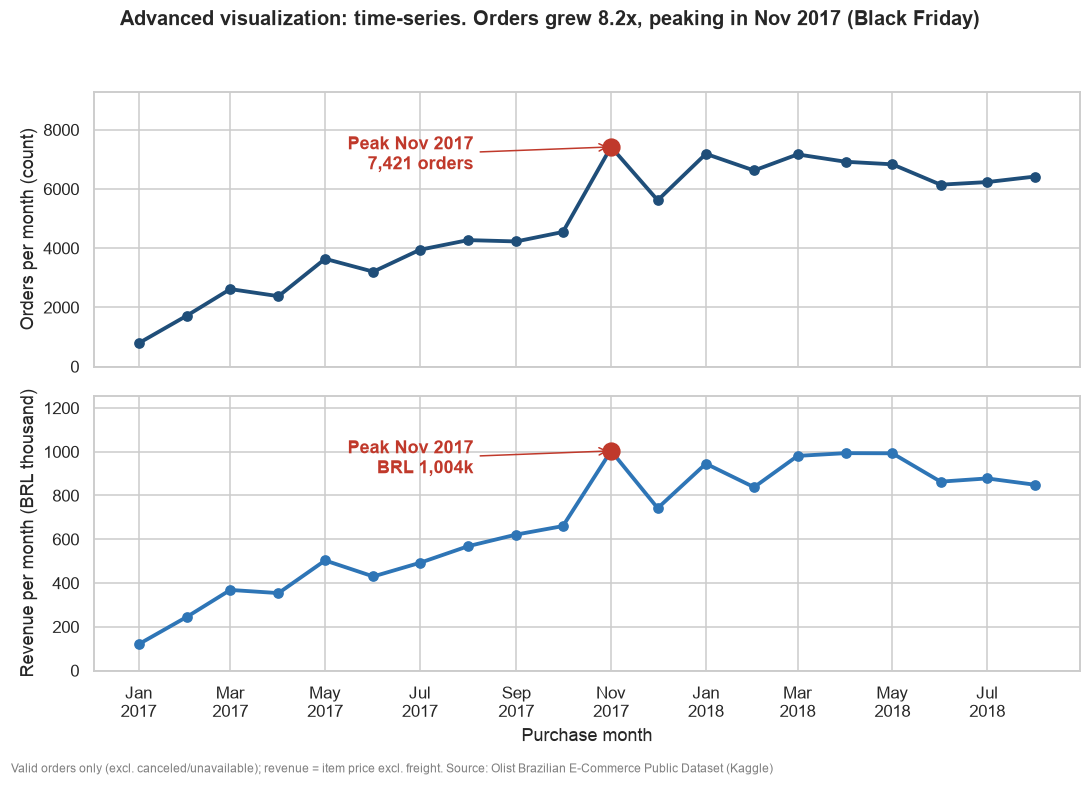

In [9]:
import matplotlib.pyplot as plt, matplotlib.dates as mdates
common.set_style()
FIG = common.FIGURES / "notebook"; FIG.mkdir(parents=True, exist_ok=True)
SOURCE = "Source: Olist Brazilian E-Commerce Public Dataset (Kaggle)"

months = pd.to_datetime(pdf["purchase_month"] + "-01")
peak = pdf.loc[pdf["orders"].idxmax()]; first, last = pdf.iloc[0], pdf.iloc[-1]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, facecolor="white")
ax1.plot(months, pdf["orders"], color=common.PRIMARY, lw=2.5, marker="o")
ax2.plot(months, pdf["revenue"] / 1e3, color=common.ACCENT, lw=2.5, marker="o")
pm = pd.to_datetime(peak.purchase_month + "-01")
for ax, y, txt in [(ax1, peak.orders, f"Peak {pm:%b %Y}\n{int(peak.orders):,} orders"),
                   (ax2, peak.revenue / 1e3, f"Peak {pm:%b %Y}\nBRL {peak.revenue/1e3:,.0f}k")]:
    ax.scatter([pm], [y], s=120, color=common.ALERT, zorder=5)
    ax.annotate(txt, (pm, y), xytext=(-90, -5), textcoords="offset points", ha="right", va="center",
                color=common.ALERT, fontweight="bold", arrowprops=dict(arrowstyle="->", color=common.ALERT))
    ax.set_ylim(0, y * 1.25)
ax1.set_ylabel("Orders per month (count)"); ax2.set_ylabel("Revenue per month (BRL thousand)")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y")); ax2.set_xlabel("Purchase month")
fig.suptitle(f"Advanced visualization: time-series. Orders grew {last.orders/first.orders:.1f}x, peaking in {pm:%b %Y} (Black Friday)",
             fontsize=13, fontweight="bold")
fig.text(0.01, -0.01, "Valid orders only (excl. canceled/unavailable); revenue = item price excl. freight. " + SOURCE, fontsize=8, color=common.GREY)
fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(FIG / "finding1_time_series.png", facecolor="white"); plt.show()

In [10]:
display(Markdown(f"""
**Result 1.** Peak month **{peak.purchase_month}** (Black Friday): **{int(peak.orders):,} orders** and **BRL {peak.revenue:,.2f}** revenue,
{peak.mom_pct:+.1f}% orders vs the month before. Orders grew **{last.orders/first.orders:.2f}x** from Jan 2017 ({int(first.orders):,}) to Aug 2018 ({int(last.orders):,}).
"""))


**Result 1.** Peak month **2017-11** (Black Friday): **7,421 orders** and **BRL 1,003,862.14** revenue,
+63.2% orders vs the month before. Orders grew **8.16x** from Jan 2017 (787) to Aug 2018 (6,421).


## Part 3 · Finding 2 — Buyers are concentrated in São Paulo  *(Advanced visualization: geospatial)*
**Say:** "Second, where do people buy? We count orders per state and place buyers on a map using their zip-code coordinates."

In [11]:
# Orders per customer state
total_orders = valid.select("order_id").distinct().count()
states = (valid.groupBy("customer_state").agg(F.countDistinct("order_id").alias("orders"))
          .withColumn("share_pct", F.round(F.col("orders") / total_orders * 100, 2)).orderBy(F.desc("orders")))
states_pd = states.toPandas()

# Geolocation has 1M rows: keep points inside Brazil and average them to ONE point per zip prefix
geo_zip = (geo_raw.filter(F.col("geolocation_lat").between(-34, 6) & F.col("geolocation_lng").between(-74, -34))
           .groupBy("geolocation_zip_code_prefix").agg(F.avg("geolocation_lat").alias("lat"), F.avg("geolocation_lng").alias("lng")))

# Orders per buyer zip prefix, joined to its coordinates
zip_orders = valid.groupBy("customer_zip").agg(F.countDistinct("order_id").alias("orders"))
points = (zip_orders.join(geo_zip, zip_orders.customer_zip == geo_zip.geolocation_zip_code_prefix)
          .toPandas())                                          # ~15k points
states.show(5)

+--------------+------+---------+
|customer_state|orders|share_pct|
+--------------+------+---------+
|            SP| 41125|    41.88|
|            RJ| 12697|    12.93|
|            MG| 11496|    11.71|
|            RS|  5415|     5.51|
|            PR|  4982|     5.07|
+--------------+------+---------+
only showing top 5 rows


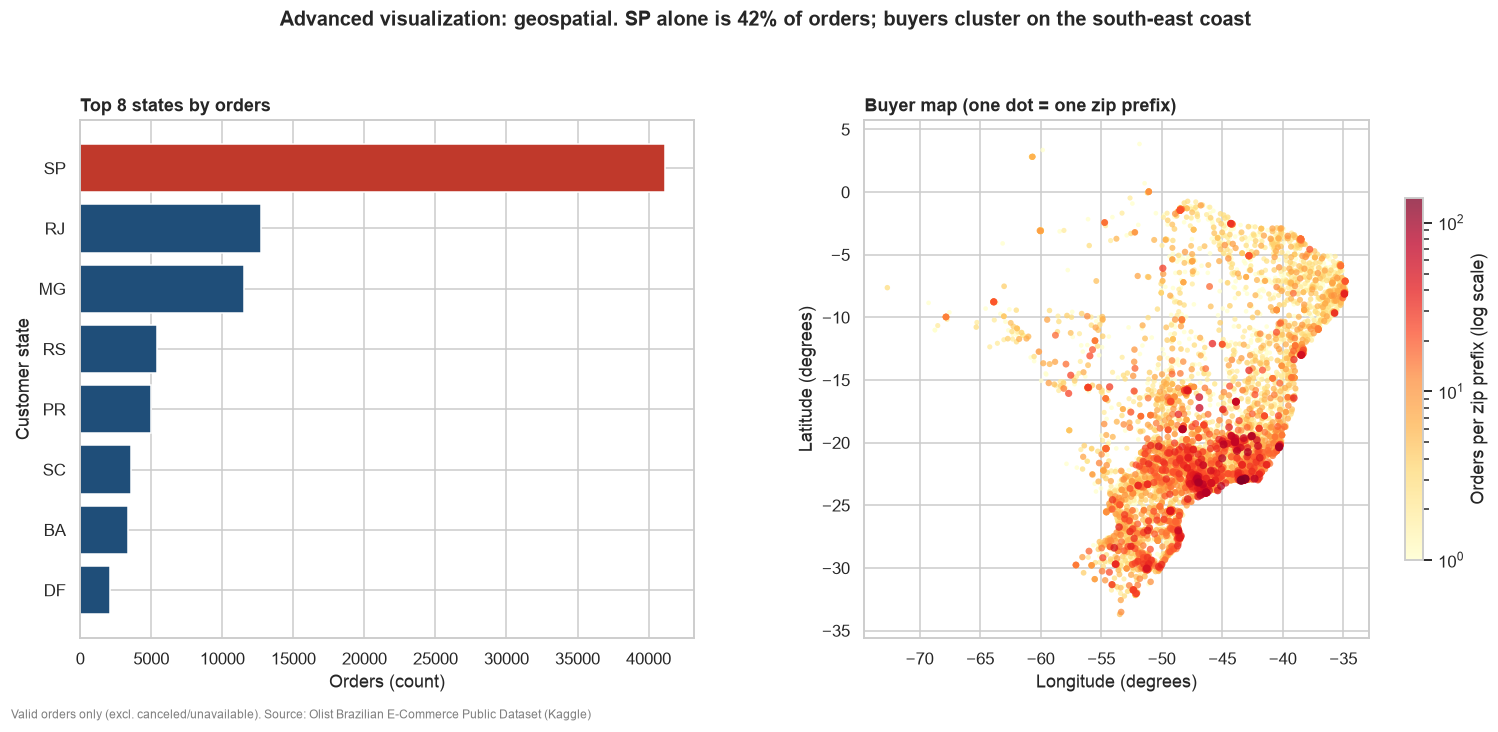

In [12]:
import numpy as np
from matplotlib.colors import LogNorm
sp = states_pd[states_pd.customer_state == "SP"].iloc[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), facecolor="white", gridspec_kw={"width_ratios": [1, 1.2]})
top = states_pd.head(8).iloc[::-1]
ax1.barh(top.customer_state, top.orders, color=[common.ALERT if s == "SP" else common.PRIMARY for s in top.customer_state])
ax1.set_xlabel("Orders (count)"); ax1.set_ylabel("Customer state"); ax1.set_title("Top 8 states by orders", loc="left", fontsize=12)
p = points.sort_values("orders")
sc = ax2.scatter(p.lng, p.lat, c=p.orders, s=6 + 5 * np.log1p(p.orders), cmap="YlOrRd",
                 norm=LogNorm(vmin=1, vmax=p.orders.max()), alpha=0.75, edgecolor="none")
fig.colorbar(sc, ax=ax2, shrink=0.7).set_label("Orders per zip prefix (log scale)")
ax2.set_aspect(1 / np.cos(np.radians(15))); ax2.set_xlabel("Longitude (degrees)"); ax2.set_ylabel("Latitude (degrees)")
ax2.set_title("Buyer map (one dot = one zip prefix)", loc="left", fontsize=12)
fig.suptitle(f"Advanced visualization: geospatial. SP alone is {sp.share_pct:.0f}% of orders; buyers cluster on the south-east coast",
             fontsize=13, fontweight="bold")
fig.text(0.01, -0.01, "Valid orders only (excl. canceled/unavailable). " + SOURCE, fontsize=8, color=common.GREY)
fig.tight_layout(rect=(0, 0, 1, 0.94)); fig.savefig(FIG / "finding2_geography.png", facecolor="white"); plt.show()

In [13]:
top3 = states_pd.head(3)
display(Markdown(f"""
**Result 2.** **SP** has {int(sp.orders):,} of {total_orders:,} valid orders = **{sp.share_pct:.2f}%**.
The top 3 states ({', '.join(top3.customer_state)}) together hold {top3.orders.sum()/total_orders*100:.1f}% of all orders.
"""))


**Result 2.** **SP** has 41,125 of 98,199 valid orders = **41.88%**.
The top 3 states (SP, RJ, MG) together hold 66.5% of all orders.


## Part 3 · Finding 3 — Late delivery lowers review scores
**Say:** "Third, does late delivery hurt reviews? We compare the average star score of on-time and late orders."

In [14]:
# Delivered orders with a known delivery result, joined to their single review (inner join: needs a review)
scored = (orders.filter((F.col("order_status") == "delivered") & F.col("is_late").isNotNull())
          .join(reviews, "order_id"))

# Average score: on-time (False) vs late (True)
by_late = scored.groupBy("is_late").agg(F.count("*").alias("orders"), F.round(F.avg("review_score"), 2).alias("avg_score"))
by_late.show()
rows = {r["is_late"]: r for r in by_late.collect()}

# Same, split by how many days early / late the parcel arrived
d = F.col("delay_days")
bucket = (F.when(d < 0, "Early").when(d == 0, "On time (0)").when(d <= 3, "Late 1-3d")
          .when(d <= 7, "Late 4-7d").when(d <= 14, "Late 8-14d").otherwise("Late >14d"))
ORDER = ["Early", "On time (0)", "Late 1-3d", "Late 4-7d", "Late 8-14d", "Late >14d"]
bpd = (scored.withColumn("bucket", bucket).groupBy("bucket")
       .agg(F.count("*").alias("orders"), F.avg("review_score").alias("avg_score")).toPandas()
       .set_index("bucket").loc[ORDER].reset_index())
bpd

+-------+------+---------+
|is_late|orders|avg_score|
+-------+------+---------+
|   true|  6381|     2.27|
|  false| 89443|     4.29|
+-------+------+---------+



,bucket,orders,avg_score
0,Early,88163,4.294114
1,On time (0),1280,4.033594
2,Late 1-3d,1852,3.291037
3,Late 4-7d,1748,2.102975
4,Late 8-14d,1446,1.670816
5,Late >14d,1335,1.723596


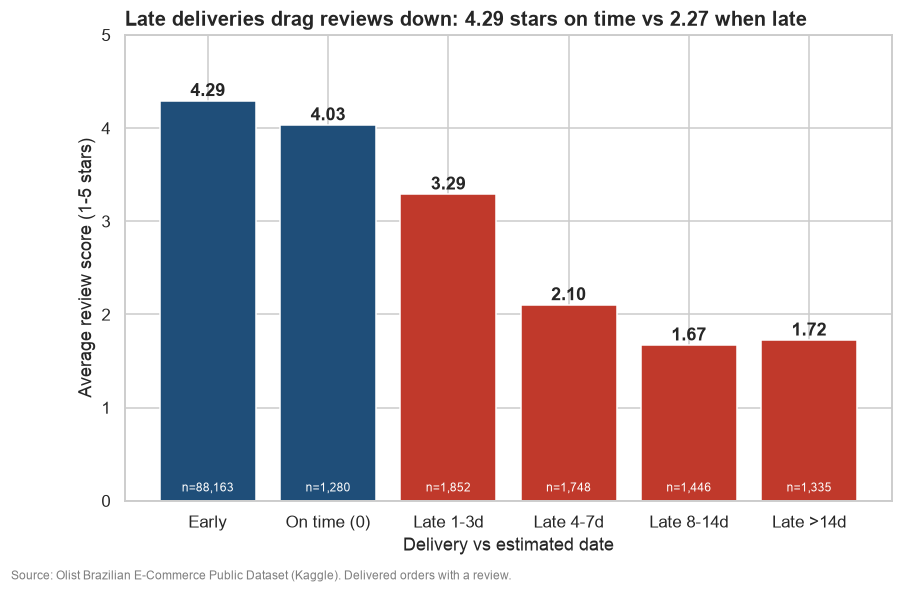

In [15]:
on, late = rows[False], rows[True]
fig, ax = plt.subplots(figsize=(9, 5.5), facecolor="white")
bars = ax.bar(bpd.bucket, bpd.avg_score, color=[common.ALERT if b.startswith("Late") else common.PRIMARY for b in bpd.bucket])
for b, s, n in zip(bars, bpd.avg_score, bpd.orders):
    ax.text(b.get_x() + b.get_width() / 2, s + 0.05, f"{s:.2f}", ha="center", fontweight="bold")
    ax.text(b.get_x() + b.get_width() / 2, 0.1, f"n={n:,}", ha="center", color="white", fontsize=8)
ax.set_ylim(0, 5); ax.set_ylabel("Average review score (1-5 stars)"); ax.set_xlabel("Delivery vs estimated date")
ax.set_title(f"Late deliveries drag reviews down: {on['avg_score']:.2f} stars on time vs {late['avg_score']:.2f} when late", loc="left", fontsize=13)
fig.text(0.01, -0.02, SOURCE + ". Delivered orders with a review.", fontsize=8, color=common.GREY)
fig.savefig(FIG / "finding3_delivery_vs_reviews.png", facecolor="white"); plt.show()

In [16]:
display(Markdown(f"""
**Result 3.** Average review score: **{on['avg_score']:.2f}** for {on['orders']:,} on-time orders vs **{late['avg_score']:.2f}** for {late['orders']:,} late orders
(a drop of {on['avg_score']-late['avg_score']:.2f} stars). The lowest score is for the \"{bpd.loc[bpd.avg_score.idxmin(), 'bucket']}\" group ({bpd.avg_score.min():.2f}).
"""))


**Result 3.** Average review score: **4.29** for 89,443 on-time orders vs **2.27** for 6,381 late orders
(a drop of 2.02 stars). The lowest score is for the "Late 8-14d" group (1.67).


## Summary
**Say:** "Three findings, each backed by Spark numbers, each leading to one business action."

| Finding | Evidence | Recommendation |
|---|---|---|
| 1. Demand peaks at Black Friday | Nov 2017 peak (7,421 orders, BRL 1.0M); orders grew about 8x in 20 months | Plan capacity, stock and promotions before sale peaks |
| 2. Buyers are concentrated in SP | SP = about 41.9% of orders; buyers cluster on the south-east coast | Recruit sellers and consider regional warehouses outside SP |
| 3. Late delivery hurts reviews | 4.29 stars on time vs 2.27 when late | Give realistic delivery estimates and send proactive delay messages |

**Syllabus tools we used:** SparkSession, DataFrames, transformations, actions, joins, groupBy / agg, window function `lag`,
Spark SQL (temp view), `cache`, lazy evaluation / `explain`, matplotlib / seaborn visualization including **time-series** and **geospatial**.

*More analysis (purchase-time heatmap, seller network graph, top categories, RDD vs DataFrame demo) is in `backup/fa2_olist_spark_FULL.ipynb` — ask us if you'd like to see it.*

In [17]:
print(f"Notebook runtime: {time.time()-T0:.0f}s")
spark.stop()

Notebook runtime: 170s
